# Relations between digits, inside a temporal rule

**The problem.** A *sequence* is a short series of 2 to 10 *steps*. Each step shows three handwritten digits, MNIST images called `x`, `y` and `z`. The sequence has one label, yes or no, that says whether it respects a **rule** about its steps. The rule is about how the digits of a step relate to each other. It uses two conditions on a step:
- the **trigger**: the digits of the step are in a relation, x < y (`Less`), or, in a harder version of the task, x + y = z (`Sum`);
- the **response**: x = y.

**The rule:** *every* step with the trigger is followed by a step with the response. It is not enough to find one trigger with its response: each trigger needs its own, so a single trigger left without a response breaks the rule and makes the label no. Otherwise the label is yes, including when there is no trigger at all: nothing can break the rule. With `Less` the response must come at a later step, since a step can't have both x < y and x = y. With `Sum` the trigger step itself also counts: (2, 2, 4) has 2 + 2 = 4 and 2 = 2, so it is its own response. This is the *Response* constraint of Declare, a standard set of temporal constraints for processes ("every request is eventually followed by a response"). With `Less`, where `z` is shown but plays no part:

| sequence (x, y per step) | trigger at | response at | label |
|---|---|---|---|
| (3, 7) (2, 2) (8, 1) | step 0 | step 1 | yes: the 3 < 7 is followed by 2 = 2 |
| (5, 5) (1, 4) (6, 0) | step 1 | step 0 | **no**: the 1 < 4 comes after the only equality |
| (9, 2) (7, 7) (8, 3) | never | step 1 | yes: no trigger, so nothing breaks the rule |

The digits themselves are never given. A network that reads the images has to learn them from the yes/no labels of the sequences; later in the notebook, 100 labelled digits are added.

**Why the task is like this.**
- **Relations between images.** Temporal benchmarks for neuro-symbolic learning, such as the one of ∂LTLf ("Time to Reason"), have one proposition per image ("this image is a 3"). Here every condition ties two or three images of a step together.
- **The format follows ∂LTLf's benchmark** where it can: lengths 2–10, 800 training sequences, the same image network.
- **Both cases are frequent.** Steps with the trigger and steps with the response are drawn more often than chance would give, and half the sequences are yes (Section 1).

**The model.** A small convolutional network reads one image and gives a probability for each of the 10 digits. sLTN writes the rule as a formula over these probabilities and trains the network so that the formula's truth value on each sequence matches the label. The rules, in words:
- **the main rule:** the label is yes exactly when every step with the trigger is followed by a step with the response;
- **two optional rules, in Section 7:** "every digit class appears somewhere", and "these 100 labelled images have their labels".

**The comparison.** A CNN + GRU: the same convolutional network on each image, a recurrent network over the steps, trained directly on the yes/no labels. It knows nothing about digits or about the rule.

**What this example shows:**
- **Relations between images inside a temporal property.** The conditions of the rule relate the images of a step ("x < y", "x + y = z") instead of describing one image.
- **Relations as fixed tables over classes.** "x < y" is a table of true/false over pairs of digit classes, "x + y = z" a table over triples; the formula turns them into relations between images.
- **Several images per step.** A step is one object that holds its three images, so the images of a step stay together instead of being paired with the images of other sequences (Section 3).
- **Defining your own quantifiers.** The rule needs ∀ as a product and ∃ as a probabilistic sum, which sLTN doesn't ship; the notebook defines them in a few lines and shows why the built-in ones don't fit (Section 4).
- **Telling a satisfied rule from a learned concept.** A network can satisfy the labels without learning the digits. The image accuracy and the confusion matrix show when this happens, and how it happens (Section 7).
- **The semantics decides what a rule means.** The rule "every class appears" does its job under one semantics and is satisfied for free under another (Section 7).
- **Adding a few labelled examples as one more rule.** 100 labelled digits enter training as one more statement, next to the rule about the sequences (Section 7).
- **Using a model on longer sequences.** The formula doesn't depend on the length, so a model trained on 2–10 steps is used on 20 steps without retraining (Section 7).

**Compute.** One sLTN training takes 2–3 minutes on a T4 GPU; the whole notebook about 30 minutes there. On a CPU it works, but takes hours. The results over 5 seeds (Section 8) come from the same code, run beforehand on a T4 GPU, and are stored in the notebook.


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

import sltn
from sltn import KB, Interpretation, Logic, Signature
from sltn.interpretation.operators.aggregator import AggregMax, AggregMin, AggregPMeanError
from sltn.interpretation.operators.base import AggregationOperator

K = 10                                                 # digit classes
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG = dict(
    n_test=1000,                        # test sequences (lengths 2-10), and as many of length 20
    steps=dict(less=4000, sum=6000),    # Adam steps, batches of 32 sequences of one length
    batch=32,
    lr=1e-3,                            # sLTN
    gru_lr=1e-4,                        # GRU (at 1e-3 it collapses to a constant answer)
    seed=0,
)
DATA = "../datasets/"
COLORS = {"sltn": "#eb6834", "labonly": "#1baf7a", "gru": "#2a78d6"}
print("sltn:", sltn.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

sltn: 0.1.0 | device: NVIDIA A40


## 1. Data

- **Steps.** To make both the trigger and the response frequent, a step has the trigger with probability 0.25, x = y with probability 0.2, and is otherwise three uniform digits.
- **Labels.** Sequences are drawn until there are as many yes as no.
- **Images.** Each digit is replaced by a random MNIST image of that class: training images for the training sequences, test images for the test sequences.
- **Lengths.** 2–10 steps for training and testing; a second test set has 20 steps, longer than any training sequence.
- **Batches hold sequences of one length**, so no padding is needed: the `geq` relation over the steps is rebuilt for each batch. (The fever-ward example, `4_FeverWard`, shows the padding pattern instead.)

In [2]:
def load_pool(train):
    ds = datasets.MNIST(DATA, train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1), ds.targets


def trigger(d, relation):
    # The trigger at every step: x + y = z ("sum") or x < y ("less"). d: [..., 3] digits.
    return d[..., 0] + d[..., 1] == d[..., 2] if relation == "sum" else d[..., 0] < d[..., 1]


def response_label(d, length, relation):
    # Response(trigger, Eq) on the first `length` steps of d: [T, 3].
    d = d[:length]
    eq = d[:, 0] == d[:, 1]
    later_eq = torch.flip(torch.cummax(torch.flip(eq.int(), [0]), 0).values, [0]).bool()   # x = y at t or later
    return bool((~trigger(d, relation) | later_eq).all())


def make_sequences(n, pool, g, relation, lmin=2, lmax=10, p_rel=0.25, p_eq=0.2):
    # n sequences, half yes; digits [n, lmax, 3] (padded), the index of each image in the pool, lengths, labels.
    by_class = [torch.nonzero(pool[1] == k).flatten() for k in range(K)]
    seqs, lengths, labels = [], [], []
    want = {True: n // 2, False: n - n // 2}
    while want[True] or want[False]:
        L = int(torch.randint(lmin, lmax + 1, (1,), generator=g))
        u = torch.rand(L, generator=g)
        x, y, z = (torch.randint(0, K, (L,), generator=g) for _ in range(3))
        rel_mode, eq_mode = u < p_rel, (u >= p_rel) & (u < p_rel + p_eq)
        if relation == "sum":
            y_sum = (torch.rand(L, generator=g) * (K - x)).long()                   # y in [0, 9 - x]
            y = torch.where(rel_mode, y_sum, torch.where(eq_mode, x, y))
            z = torch.where(rel_mode, x + y, z)
        else:
            x_l = (torch.rand(L, generator=g) * (K - 1)).long()                     # x in [0, 8]
            y_l = x_l + 1 + (torch.rand(L, generator=g) * (K - 1 - x_l)).long()     # y in [x + 1, 9]
            x = torch.where(rel_mode, x_l, x)
            y = torch.where(rel_mode, y_l, torch.where(eq_mode, x, y))
        d = torch.stack([x, y, z], 1)
        lab = response_label(d, L, relation)
        if want[lab]:
            want[lab] -= 1
            seqs.append(F.pad(d, (0, 0, 0, lmax - L))); lengths.append(L); labels.append(lab)
    digits = torch.stack(seqs)
    pick = torch.empty_like(digits)
    for k in range(K):
        m = digits == k
        pick[m] = by_class[k][torch.randint(0, len(by_class[k]), (int(m.sum()),), generator=g)]
    perm = torch.randperm(n, generator=g)
    return dict(digits=digits[perm], img_idx=pick[perm], length=torch.tensor(lengths)[perm],
                label=torch.tensor(labels)[perm])


class Data:
    # Sequences and their image pool, on DEVICE. Every batch holds sequences of one length.
    def __init__(self, seqs, images):
        self.pool = images.to(DEVICE)
        self.s = {k: v.to(DEVICE) for k, v in seqs.items()}
        self.n = len(self.s["length"])

    def batch(self, idx):
        L = int(self.s["length"][idx].max())
        imgs = self.pool[self.s["img_idx"][idx, :L]]                   # [B, L, 3, 1, 28, 28]
        return imgs, self.s["label"][idx].float(), self.s["digits"][idx, :L]

    def random_batches(self, batch, steps, g):
        lengths = self.s["length"].cpu()
        for _ in range(steps):
            L = int(lengths[torch.randint(0, self.n, (1,), generator=g)])   # lengths as frequent as in the data
            same = torch.nonzero(lengths == L).flatten()
            yield self.batch(same[torch.randint(0, len(same), (batch,), generator=g)].to(DEVICE))

    def all_batches(self, batch=200):
        lengths = self.s["length"].cpu()
        for L in lengths.unique().tolist():
            idx = torch.nonzero(lengths == L).flatten()
            for s in range(0, len(idx), batch):
                yield self.batch(idx[s:s + batch].to(DEVICE))


def make_sets(relation, n_train, seed, pools):
    gen = lambda base: torch.Generator().manual_seed(base + seed)
    tr, te = pools["train"], pools["test"]
    return dict(train=Data(make_sequences(n_train, tr, gen(1000), relation), tr[0]),
                test=Data(make_sequences(CONFIG["n_test"], te, gen(5000), relation), te[0]),
                test_long=Data(make_sequences(CONFIG["n_test"], te, gen(7000), relation, lmin=20, lmax=20), te[0]))


pools = {"train": load_pool(True), "test": load_pool(False)}
sets = make_sets("less", 800, CONFIG["seed"], pools)
tr = sets["train"].s
print(f"800 training sequences: {tr['label'].float().mean():.0%} yes, lengths {tr['length'].min()}–{tr['length'].max()}, "
      f"{int(tr['length'].sum()) * 3} images")

800 training sequences: 50% yes, lengths 2–10, 14229 images


Two training sequences, each read under both rules. Each column is a step, with its images `x`, `y`, `z` from top to bottom; below a column are the conditions that hold there: the trigger of `Less` (x < y), the trigger of `Sum` (x + y = z) and the response (x = y). `Less` ignores `z`.
- **Sequence 366, yes under both rules.** `Less`: the only trigger, 4 < 9 at step 1, is followed by 5 = 5 at step 2. `Sum`: the only trigger, 2 + 2 = 4 at step 3, has 2 = 2 at the same step, so it is its own response.
- **Sequence 207, no under both rules.** `Less`: the trigger 6 < 7 at the last step has no step after it. `Sum`: the trigger 4 + 1 = 5 at step 3 has no response, since none of steps 3, 4 and 5 has x = y. The trigger 2 + 2 = 4 at step 2 is fine (it is its own response), but it doesn't help step 3: each trigger needs its own response, at its step or later.

Both come from the `Less` training set, which stores the `Less` label. The `Sum` task draws its own sequences, with more steps where x + y = z.

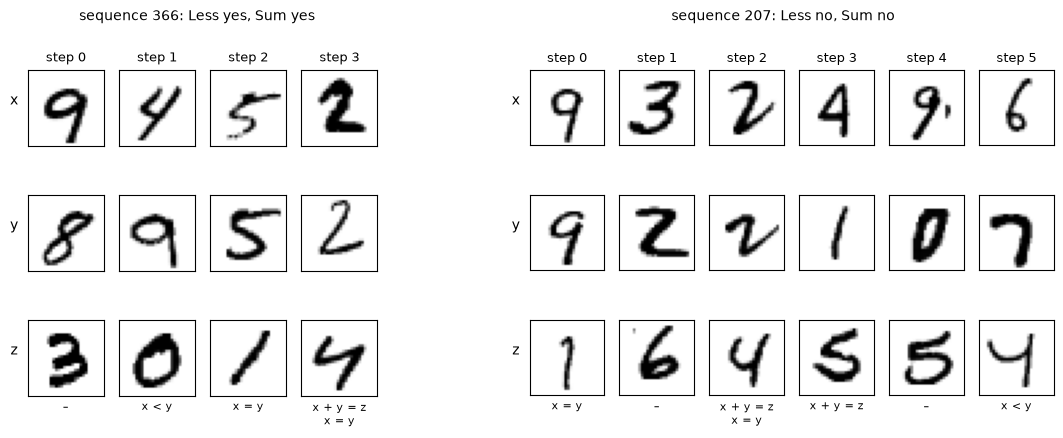

sequence 366, digits (x, y, z): [(9, 8, 3), (4, 9, 0), (5, 5, 1), (2, 2, 4)]
  less: trigger (x < y) at steps [1], response (x = y) at steps [2, 3] -> yes
  sum : trigger (x + y = z) at steps [3], response (x = y) at steps [2, 3] -> yes
sequence 207, digits (x, y, z): [(9, 9, 1), (3, 2, 6), (2, 2, 4), (4, 1, 5), (9, 0, 5), (6, 7, 4)]
  less: trigger (x < y) at steps [5], response (x = y) at steps [0, 2] -> no
  sum : trigger (x + y = z) at steps [2, 3], response (x = y) at steps [0, 2] -> no


In [3]:
def conditions(d):
    # The conditions that hold at each step: the Less trigger, the Sum trigger, the response.
    less, total, eq = trigger(d, "less"), trigger(d, "sum"), d[:, 0] == d[:, 1]
    return ["\n".join(n for n, h in (("x < y", less[t]), ("x + y = z", total[t]), ("x = y", eq[t])) if h) or "–"
            for t in range(len(d))]


yes_no = lambda b: "yes" if b else "no"
SHOW = (366, 207)       # two training sequences: yes under both rules, then no under both
fig = plt.figure(figsize=(11.5, 4.6))
for sf, k in zip(fig.subfigures(1, 2, width_ratios=[4, 6], wspace=0.04), SHOW):
    L = int(tr["length"][k])
    d = tr["digits"][k, :L].cpu()
    imgs = pools["train"][0][tr["img_idx"][k, :L].cpu()]
    axes = sf.subplots(3, L)
    for t, cond in enumerate(conditions(d)):
        for r, name in enumerate("xyz"):
            ax = axes[r, t]
            ax.imshow(imgs[t, r, 0], cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
            if t == 0:
                ax.set_ylabel(name, rotation=0, labelpad=10)
        axes[0, t].set_title(f"step {t}", fontsize=9)
        axes[-1, t].set_xlabel(cond, fontsize=8, va="top")
    sf.suptitle(f"sequence {k}: Less {yes_no(response_label(d, L, 'less'))}, Sum {yes_no(response_label(d, L, 'sum'))}",
                fontsize=10)
plt.show()

for k in SHOW:
    L = int(tr["length"][k])
    d = tr["digits"][k, :L].cpu()
    assert response_label(d, L, "less") == bool(tr["label"][k])          # the label this training set stores
    print(f"sequence {k}, digits (x, y, z):", [tuple(v) for v in d.tolist()])
    for relation, condition in (("less", "x < y"), ("sum", "x + y = z")):
        print(f"  {relation:4s}: trigger ({condition}) at steps {torch.nonzero(trigger(d, relation)).flatten().tolist()}, "
              f"response (x = y) at steps {torch.nonzero(d[:, 0] == d[:, 1]).flatten().tolist()}"
              f" -> {yes_no(response_label(d, L, relation))}")

## 2. The networks

- **`DigitNet`**, the image network of ∂LTLf: two 5×5 convolutions (32 and 64 filters), a 1024-unit layer with dropout, a softmax over the 10 classes. sLTN uses it as the function `digit`.
- **The baseline, `GRUBaseline`:** the same convolutional trunk on each image, the three feature vectors of a step concatenated, a GRU over the steps, and a yes/no output trained with binary cross-entropy. It has no notion of digits, so its image representation is scored with a **linear probe** (below).

**The linear probe** measures what a trained trunk has learned about digits, without changing it. After training, the trunk of the model is frozen (no gradients, dropout off) and turns 100 labelled training images, 10 per class, into their 1,024 features. A logistic regression is fit from these features to the digits, then scored on the images of the test sequences.
- **Only the logistic regression learns.** It puts names on the groups of images that the trunk already separates.
- **It is linear, so it can't add knowledge.** It can't pull apart images that the trunk's features mix. A high probe accuracy means the trunk already tells the digits apart, even when the model was never told about digits. But an untrained trunk, with random weights, already gets about 0.74 (0.731–0.747 over 3 random initialisations): random convolutions and a linear classifier read MNIST fairly well. Only a probe well above that shows learned features.
- **It is computed for every model.** For the GRU it is the only way to see what its trunk learned, since the GRU has no digit output. For sLTN it can be compared with the image accuracy of `digit`, and the two can differ: with the rule only and 20,000 sequences (Section 7), the probe is 0.95 and the image accuracy 0.11. The trunk separates the digits, but `digit` merges them into a few classes.

In [4]:
class Trunk(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 5), nn.ReLU(), nn.MaxPool2d(2),          # 28 -> 24 -> 12
            nn.Conv2d(32, 64, 5), nn.ReLU(), nn.MaxPool2d(2),         # 12 -> 8 -> 4
            nn.Flatten(), nn.Linear(64 * 4 * 4, 1024), nn.ReLU(), nn.Dropout(0.5))

    def forward(self, x):
        return self.net(x)


class DigitNet(nn.Module):
    # [N, 1, 28, 28] -> [N, 10] class probabilities
    def __init__(self):
        super().__init__()
        self.trunk, self.head = Trunk(), nn.Linear(1024, K)

    def forward(self, x):
        return torch.softmax(self.head(self.trunk(x)), -1)


class GRUBaseline(nn.Module):
    # [B, L, 3, 1, 28, 28] -> [B] logits of "yes"
    def __init__(self, hidden=128):
        super().__init__()
        self.trunk = Trunk()
        self.gru = nn.GRU(3 * 1024, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, imgs):
        B, L = imgs.shape[:2]
        _, h = self.gru(self.trunk(imgs.flatten(0, 2)).view(B, L, 3 * 1024))
        return self.out(h[-1]).squeeze(-1)

## 3. sLTN: the signature and the formulas

**One individual per step, holding its three images.** The sort `Step` has values of shape `[3, 1, 28, 28]`, and a sequence is a variable `s` over the dimension `T`. The functions `sx`, `sy`, `sz` pick one of the three images, so `digit(sx(s[t]))` is the class distribution of image `x` at step `t`.

**The relations are truth tables over classes.** `Less(c, c1)` is 1 when c < c1, `Add(c, c1, c2)` is 1 when c + c1 = c2. They are applied to one-hot classes; the variables `c`, `c1`, `c2`, `c3` range over the 10 one-hot classes. `Is(p, c)` is the probability that `p` gives to the class `c`.

**The formulas:**
- `TRIGGER[relation]`, true at step `t` if the trigger holds (one formula per task, `less` or `sum`): `∃ c, c1: (Less(c, c1) & Is(digit(sx(s[t])), c) & Is(digit(sy(s[t])), c1))`;
- `EQ`, true at step `t1` if x = y: `∃ c3: (Is(digit(sx(s[t1])), c3) & Is(digit(sy(s[t1])), c3))`;
- `ANSWER`, the model's answer for each sequence: `∀ t: (TRIGGER → ∃ t1 | geq(t, t1): EQ)`, where `geq(t, t1)` holds when step `t1` is step `t` or later;
- `RULE`, the training clause: `∀ (s, l): (Yes(l) ↔ ANSWER)`, with `l` the sequence's label (1 or 0) and `Yes(l)` true when `l` is 1.

**Why one variable `s` for the steps, and not three variables `x`, `y`, `z`, one per image?** In a batch of B sequences, `x` would hold B sequences of images: for each sequence, its `x` image at every step; `y` and `z` likewise. sLTN gives every free variable its own axis, so a formula with the free variables `x`, `y` and `z` has a value for every combination of the `x` images of one sequence, the `y` images of another and the `z` images of a third: a B × B × B table, where most entries mix different sequences. (The steps aren't crossed: `x[t]`, `y[t]` and `z[t]` share the structural variable `t`.)
- **In `RULE` this is harmless:** `RULE` wraps `ANSWER` in `∀ (x, y, z, l)`, which pairs the i-th `x` with the i-th `y`, `z` and `l`, so only the combinations of one sequence count.
- **At test time `ANSWER` is evaluated outside `RULE`:** to read the model's yes/no for each test sequence, the notebook evaluates `ANSWER` by itself, with no quantifier over the sequences around it, so each sequence keeps its own value. With `x`, `y`, `z` nothing would pair them: it would return the B × B × B table, and the answer for sequence i would be the entry (i, i, i).
- **Diagonal quantification doesn't help here.** It is part of a quantifier: `∀ (x, y, z): ANSWER` pairs the sequences correctly, but it also aggregates over them and returns one number for the whole batch, not one answer per sequence. sLTN has no way to pair variables and leave them free. The only ways left are to compute the B × B × B table and keep its diagonal (for a scoring batch of 200 sequences, 8 million combinations per step to keep 200), or to evaluate one sequence at a time.

With one variable `s`, whose value holds the three images of a step, the images of a step can't be separated, and `ANSWER` returns one value per sequence.

Two more clauses, used in Section 7: `COVER`, "every class appears somewhere in the batch", and `DIGIT_LABELS`, "the labelled images have their labels".

In [5]:
sig = Signature("digit_relations")
for sort in ("Step", "Image", "Class", "Probs", "Label"):
    sig.sort(sort)
sig.dimension("T")
sig.structural_variable("t", "T")
sig.variable("s", "Step", dims=["T"])            # a sequence: one Step per t, each with three images
sig.variable("l", "Label")                        # its yes/no label
sig.variable("c", "Class")                        # the 10 one-hot classes (c1, c2, c3 are aliases)
sig.variable("li", "Image")                       # the labelled digits of Section 7
sig.variable("ld", "Class")                       # and their one-hot labels
for f in ("sx", "sy", "sz"):
    sig.function(f, ["Step"], "Image")            # the image of stream x, y or z
sig.function("digit", ["Image"], "Probs")
sig.predicate("Is", ["Probs", "Class"])
sig.predicate("Add", ["Class", "Class", "Class"])
sig.predicate("Less", ["Class", "Class"])
sig.predicate("Yes", ["Label"])
sig.structural_relation("geq", ["T", "T"])      # geq(t, t1): t1 is t or later

TRIGGER = {
    "sum": "(∃ c, c1, c2: (Add(c, c1, c2) & Is(digit(sx(s[t])), c) & Is(digit(sy(s[t])), c1) & Is(digit(sz(s[t])), c2)))",
    "less": "(∃ c, c1: (Less(c, c1) & Is(digit(sx(s[t])), c) & Is(digit(sy(s[t])), c1)))",
}
EQ = "(∃ c3: (Is(digit(sx(s[t1])), c3) & Is(digit(sy(s[t1])), c3)))"
ANSWER = {r: sig.parse(f"∀ t: ({a} -> (∃ t1 | geq(t, t1): {EQ}))") for r, a in TRIGGER.items()}
RULE = {r: sig.parse(f"∀ (s, l): (Yes(l) <-> (∀ t: ({a} -> (∃ t1 | geq(t, t1): {EQ}))))") for r, a in TRIGGER.items()}
COVER = sig.parse("∀ c: (∃ s: (∃ t: (Is(digit(sx(s[t])), c) ∨ Is(digit(sy(s[t])), c) ∨ Is(digit(sz(s[t])), c))))")
DIGIT_LABELS = sig.parse("∀ (li, ld): Is(digit(li), ld)")

ADD = torch.zeros(K, K, K)
for a in range(K):
    for b in range(K - a):
        ADD[a, b, a + b] = 1
LESS = torch.ones(K, K).triu(1)                    # LESS[i, j] = 1 iff i < j
print(ANSWER["less"])

∀ t: ((∃ c, c1: (Less(c, c1) & (Is(digit(sx(s[t])), c) & Is(digit(sy(s[t])), c1)))) → (∃ t1 | geq(t, t1): ∃ c3: (Is(digit(sx(s[t1])), c3) & Is(digit(sy(s[t1])), c3))))


## 4. Product semantics: defining your own aggregators

The answer is a ∀ over the steps of an implication whose right side is an ∃ over the later steps. How these quantifiers are computed matters:
- **∀ over the steps must be strict.** One trigger without a response makes the answer "no". The p-means that sLTN uses by default average the steps: with pMeanError (p = 2), a sequence with 5 good steps and 1 trigger without a response still scores 0.59, so a "no" can't be told from a "yes". ∀ must be the minimum or the product.
- **∃ should spread its gradient.** The response is "some step at `t` or later has x = y", and early in training the model doesn't know which step that is. The maximum passes the gradient to the step that looks likeliest only, so a wrong early guess gets all the signal; the probabilistic sum 1 − ∏(1 − x) gives step i the gradient ∏ⱼ≠ᵢ(1 − xⱼ), the chance that no other step is the response, so every candidate is pushed. Tested with rule + 100 labelled digits, changing only this ∃ (5 seeds of `Less`, 3 of `Sum`, run beforehand on a GPU): when training works, max reaches the same accuracy (0.94–0.95), but it collapsed to a constant answer on 1 of 8 runs, the probabilistic sum on none.

∂LTLf uses product semantics: ∀ = product, ∃ = probabilistic sum. sLTN ships min, max and the p-means but no product, so here they are, as subclasses of `AggregationOperator`. An aggregator gets the values `xs`, the axes `dim` to reduce, `keepdim`, and an optional `mask` (1 where an entry counts, for guards such as `| geq(t, t1)`) and must also define `__repr__`.

In [6]:
def _dims(x, dim):
    return tuple(range(x.dim())) if dim is None else (tuple(dim) if isinstance(dim, (tuple, list)) else (dim,))


class AggregProd(AggregationOperator):
    # ∀ as the product of the values. Masked-out entries count as 1 (they don't constrain).
    def __call__(self, xs, dim=None, keepdim=False, mask=None):
        x = xs if mask is None else 1 - mask * (1 - xs)
        return torch.exp(torch.log(x.clamp(min=1e-6)).sum(dim=_dims(x, dim), keepdim=keepdim))

    def __repr__(self):
        return "AggregProd()"


class AggregProbSum(AggregationOperator):
    # ∃ as the probabilistic sum 1 - ∏(1 - x). Masked-out entries count as 0 (they can't witness).
    def __call__(self, xs, dim=None, keepdim=False, mask=None):
        x = xs if mask is None else mask * xs
        return 1 - torch.exp(torch.log1p(-x.clamp(max=1 - 1e-6)).sum(dim=_dims(x, dim), keepdim=keepdim))

    def __repr__(self):
        return "AggregProbSum()"


steps = torch.tensor([1.0, 1.0, 1.0, 1.0, 1.0, 0.0])          # 5 good steps, 1 trigger without a response
print("∀ over 5 good steps and 1 bad one:")
for name, agg in [("pMeanError p=2", AggregPMeanError(p=2)), ("min", AggregMin()), ("product", AggregProd())]:
    print(f"  {name:15s} {agg(steps, dim=0).item():.2f}")

later = torch.tensor([0.1, 0.3, 0.2], requires_grad=True)       # chance that x = y at each later step
print("∃ over 3 later steps, value and gradient:")
for name, agg in [("max", AggregMax()), ("probabilistic sum", AggregProbSum())]:
    later.grad = None
    v = agg(later, dim=0); v.backward()
    print(f"  {name:18s} {v.item():.2f}  gradient {[round(g, 2) for g in later.grad.tolist()]}")

∀ over 5 good steps and 1 bad one:
  pMeanError p=2  0.59
  min             0.00
  product         0.00
∃ over 3 later steps, value and gradient:
  max                0.30  gradient [0.0, 1.0, 0.0]
  probabilistic sum  0.50  gradient [0.56, 0.72, 0.63]


The interpretation sets the aggregators by logic key: `"forall,t"` and `"exists,t"` for the quantifiers over the steps, `"exists"` for the ∃ over the classes. With `semantics="godel"` they are min and max instead. The rest are the defaults (product ∧, Reichenbach →).

In [7]:
def make_interp(semantics, net, image_shape=(1, 28, 28)):
    lg = Logic().with_defaults()
    if semantics == "prod":
        lg["forall,t"], lg["exists,t"], lg["exists"] = AggregProd(), AggregProbSum(), AggregProbSum()
    else:
        lg["forall,t"], lg["exists,t"], lg["exists"] = AggregMin(), AggregMax(), AggregMax()
    it = Interpretation(sig, logic=lg)
    it["Step"] = sltn.Type("step", shape=(3, *image_shape))
    it["Image"] = sltn.Type("image", shape=image_shape)
    it["Class"] = sltn.Type("class", shape=(K,))
    it["Probs"] = sltn.Type("probs", shape=(K,))
    it["Label"] = sltn.Type("label", shape=(1,))
    it["sx"], it["sy"], it["sz"] = (lambda v: v[:, 0]), (lambda v: v[:, 1]), (lambda v: v[:, 2])
    it["digit"] = net
    it["Is"] = lambda p, c: (p * c).sum(-1, keepdim=True)
    add, less = ADD.to(DEVICE), LESS.to(DEVICE)
    it["Add"] = lambda a, b, c: torch.einsum("ijk,ni,nj,nk->n", add, a, b, c).unsqueeze(-1)
    it["Less"] = lambda a, b: torch.einsum("ij,ni,nj->n", less, a, b).unsqueeze(-1)
    it["Yes"] = lambda v: v
    it["c"] = torch.eye(K, device=DEVICE)
    return it.to(DEVICE)


def ground(it, imgs, labels):
    # One batch: the sequences, their labels, and geq over its L steps.
    L = imgs.shape[1]
    it["s"] = imgs
    it["l"] = labels.unsqueeze(-1)
    it["geq"] = torch.ones(L, L, device=DEVICE).triu()           # geq[t, t1] = 1 iff t1 >= t

## 5. Sanity check: with perfect digits, the formula gives the labels

Before training anything: if `digit` were perfect, would the formula answer every sequence correctly? Here every image is replaced by the one-hot vector of its digit and `digit` is the identity. Both semantics should get every sequence right, with values near 1 on the yes and near 0 on the no.

In [8]:
@torch.no_grad()
def perfect_digits_check(relation, semantics, n=1000):
    seqs = make_sequences(n, (torch.eye(K), torch.arange(K)), torch.Generator().manual_seed(0), relation)
    data = Data(seqs, torch.eye(K))                                # "image" k = one-hot of class k
    it = make_interp(semantics, nn.Identity(), image_shape=(K,))
    ok, vals = 0, {True: [], False: []}
    for imgs, lab, _ in data.all_batches():
        ground(it, imgs, lab)
        v = it(ANSWER[relation]).value.squeeze(-1)
        ok += ((v > 0.5) == lab.bool()).sum().item()
        for b in (True, False):
            vals[b] += v[lab.bool() == b].tolist()
    return ok / n, np.mean(vals[True]), np.mean(vals[False])


for relation in ("less", "sum"):
    for semantics in ("prod", "godel"):
        acc, yes, no = perfect_digits_check(relation, semantics)
        print(f"{relation:4s} {semantics:5s}: accuracy {acc:.3f}, mean answer {yes:.3f} on yes, {no:.3f} on no")

less prod : accuracy 1.000, mean answer 1.000 on yes, 0.000 on no


less godel: accuracy 1.000, mean answer 1.000 on yes, 0.000 on no
sum  prod : accuracy 1.000, mean answer 1.000 on yes, 0.000 on no


sum  godel: accuracy 1.000, mean answer 1.000 on yes, 0.000 on no


## 6. Training and scoring

- **sLTN** minimises 1 − the satisfaction of its clauses, one batch of 32 sequences of one length at a time. The clauses are the `RULE`, optionally `COVER`, optionally `DIGIT_LABELS`.
- **The GRU** minimises binary cross-entropy on the labels.
- For one seed, every model sees the same sequences in the same order.

**Scores, on 1,000 test sequences:**
- **sequence accuracy:** sLTN answers with `ANSWER` > 0.5, computed with its own `digit`; on lengths 2–10, and on length 20;
- **image accuracy:** `digit`'s argmax against the true digit, on every test image (sLTN only);
- **the confusion matrix:** for each true digit, the share of its images given each class;
- **probe accuracy:** the linear probe of Section 2, for every model.

In [9]:
def labelled_digits(n_per_class=10):
    # 100 labelled training images, 10 per class; the probe uses the same ones.
    imgs, digits = pools["train"]
    idx = torch.cat([torch.nonzero(digits == k).flatten()[:n_per_class] for k in range(K)])
    return imgs[idx].to(DEVICE), F.one_hot(digits[idx], K).float().to(DEVICE)


def train_sltn(sets, relation, semantics="prod", rule=True, cover=False, labels=False, seed=CONFIG["seed"]):
    torch.manual_seed(seed)
    net = DigitNet().to(DEVICE)
    it = make_interp(semantics, net)
    kb = KB(([RULE[relation]] if rule else []) + ([COVER] if cover else []) + ([DIGIT_LABELS] if labels else []))
    if labels:
        it["li"], it["ld"] = labelled_digits()
    opt = torch.optim.Adam(net.parameters(), lr=CONFIG["lr"])
    batches = sets["train"].random_batches(CONFIG["batch"], CONFIG["steps"][relation], torch.Generator().manual_seed(seed))
    for imgs, lab, _ in batches:
        ground(it, imgs, lab)
        opt.zero_grad()
        (1 - it(kb).value.squeeze()).backward()
        opt.step()
    net.eval()

    @torch.no_grad()
    def answer(imgs, lab):
        ground(it, imgs, lab)
        r = it(ANSWER[relation])
        assert r.axis_names[0] == "s"                              # one value per sequence
        return r.value.squeeze(-1) > 0.5

    return net, answer


def train_gru(sets, relation, seed=CONFIG["seed"]):
    torch.manual_seed(seed)
    net = GRUBaseline().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=CONFIG["gru_lr"])
    for imgs, lab, _ in sets["train"].random_batches(CONFIG["batch"], CONFIG["steps"][relation],
                                                     torch.Generator().manual_seed(seed)):
        opt.zero_grad()
        F.binary_cross_entropy_with_logits(net(imgs), lab).backward()
        opt.step()
    net.eval()
    return net, torch.no_grad()(lambda imgs, lab: net(imgs) > 0)


@torch.no_grad()
def seq_acc(answer, data):
    ok = sum((answer(imgs, lab) == lab.bool()).sum().item() for imgs, lab, _ in data.all_batches())
    return ok / data.n


@torch.no_grad()
def image_acc(net, data):
    conf = torch.zeros(K, K)                                       # [true digit, predicted class]
    for imgs, _, d in data.all_batches():
        pred = net(imgs.flatten(0, 2)).argmax(-1).view(d.shape)
        conf += torch.bincount((d * K + pred).flatten().cpu(), minlength=K * K).view(K, K)
    return (conf.diag().sum() / conf.sum()).item(), conf / conf.sum(1, keepdim=True)


@torch.no_grad()
def probe_acc(trunk, data):
    from sklearn.linear_model import LogisticRegression
    imgs, onehot = labelled_digits()
    clf = LogisticRegression(max_iter=2000).fit(trunk(imgs).cpu().numpy(), onehot.argmax(-1).cpu().numpy())
    ok = n = 0
    for b, _, d in data.all_batches():
        pred = torch.tensor(clf.predict(trunk(b.flatten(0, 2)).cpu().numpy())).view(d.shape)
        ok += (pred == d.cpu()).sum().item(); n += d.numel()
    return ok / n


def evaluate(name, sets, relation, model="sltn", **kw):
    t0 = time.perf_counter()
    net, answer = train_gru(sets, relation) if model == "gru" else train_sltn(sets, relation, **kw)
    r = dict(name=name, train_seq=seq_acc(answer, sets["train"]), seq=seq_acc(answer, sets["test"]),
             seq_long=seq_acc(answer, sets["test_long"]), probe=probe_acc(net.trunk, sets["test"]))
    if model != "gru":
        r["img"], r["confusion"] = image_acc(net, sets["test"])
    r["seconds"] = time.perf_counter() - t0
    img = f"image {r['img']:.3f}" if "img" in r else "image —    "
    print(f"{name:34s} sequences: train {r['train_seq']:.3f}, test {r['seq']:.3f}, length 20 {r['seq_long']:.3f} | "
          f"{img} | probe {r['probe']:.3f} ({r['seconds']:.0f}s)", flush=True)
    return r


def show_confusion(results):
    fig, axes = plt.subplots(1, len(results), figsize=(3.3 * len(results), 3.4))
    for ax, r in zip(np.atleast_1d(axes), results):
        ax.imshow(r["confusion"], cmap="Oranges", vmin=0, vmax=1)
        ax.set_xticks(range(K)); ax.set_yticks(range(K))
        ax.set_xlabel("class given by digit"); ax.set_ylabel("true digit")
        ax.set_title(f"{r['name']}\nimage acc {r['img']:.2f}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

## 7. What the sequence labels can and can't teach

The `Less` task first, product semantics, seed 0. Each step below changes one thing.

### 7.1 With 800 sequences: memorisation

∂LTLf's dataset size: 800 training sequences, about 14,000 images, one bit of supervision per sequence.

In [10]:
less800 = sets                                                    # built in Section 1
memo = evaluate("rule only, 800 sequences", less800, "less")

rule only, 800 sequences           sequences: train 0.994, test 0.653, length 20 0.661 | image 0.120 | probe 0.730 (68s)


The training sequences are all answered correctly, the test sequences only about two in three (0.65, chance is 0.5), and the image accuracy is at chance (0.1). The probe, 0.73, is what an untrained trunk gets (Section 2): nothing digit-like was learned. With 800 bits of supervision and 14,000 images, the network can give the images classes that satisfy every training label without being the correct digits: **a satisfied knowledge base isn't a learned concept.** This is not yet a reasoning shortcut: the classes fit the training sequences one image at a time, with no consistent mapping behind them, so they fail on new sequences. A reasoning shortcut (next section) maps every image of a digit to the same wrong class, and still answers most new sequences right. (The GRU memorises in the same way: Section 7.4.)

### 7.2 With 20,000 sequences: a reasoning shortcut

25 times more sequences, same number of steps.

rule only, 20,000 sequences        sequences: train 0.867, test 0.854, length 20 0.832 | image 0.107 | probe 0.947 (67s)


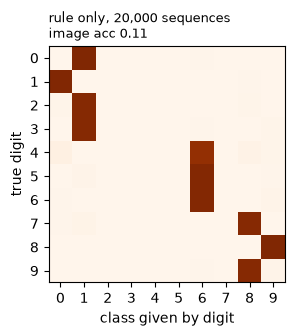

In [11]:
less20k = make_sets("less", 20000, CONFIG["seed"], pools)
shortcut = evaluate("rule only, 20,000 sequences", less20k, "less")
show_confusion([shortcut])

The sequence accuracy rises well above chance, and the probe shows that the trunk now separates the digits. Yet the image accuracy is still near 0.1: `digit` hasn't learned *the* digits, but **merged them into a few ordered groups** (the confusion matrix: several true digits per column, and unused classes). 

**Why merging works for `Less`.** The groups keep the order of the digits: {0, 2, 3} go to class 1, {4, 5, 6} to class 6, {7, 9} to class 8 (and 1, 8 to classes 0, 9). Two digits in different groups are compared right; two digits in the same group are read as x = y. Of the 45 pairs a < b, 36 keep their order, 7 are read as equal and 2 are reversed (0 and 1, 8 and 9). Reading a pair as equal does two things, and both push the label towards yes:
- **the trigger disappears:** a step with x < y is read as x = y, so it no longer needs a response;
- **a false response appears:** that step now has x = y, which answers every trigger before it.

So the yes sequences stay yes, and only some no sequences are misread. Applied to the true digits of the test sequences, this mapping (read from the confusion matrix) keeps 98% of the yes labels and 77% of the no labels, 88% overall, close to the model's 0.85. A model that learns a few coarse groups of digits gets most labels right without learning ten digits.

This is a *reasoning shortcut*: a wrong labelling of the concepts that satisfies the knowledge almost as well as the right one. It is a local optimum, not a better solution: on exact predictions such a collapse satisfies the rule at about 0.66, the true digits at about 1.

### 7.3 First way out, in logic: "every class is used"

If all 10 classes have to appear, merging digits is no longer possible, and the only labelling that keeps every `x < y` right is the identity. In sLTN this is one more clause, over the batch:

`COVER = ∀ c: ∃ s: ∃ t: (Is(digit(sx(s[t])), c) ∨ Is(digit(sy(s[t])), c) ∨ Is(digit(sz(s[t])), c))`

(In sLTN, `|` introduces a guard; disjunction is `∨` or `or`.) Tried with both semantics:

rule + cover, product              sequences: train 0.864, test 0.857, length 20 0.829 | image 0.291 | probe 0.920 (91s)


rule + cover, Gödel                sequences: train 0.944, test 0.952, length 20 0.944 | image 0.376 | probe 0.944 (94s)


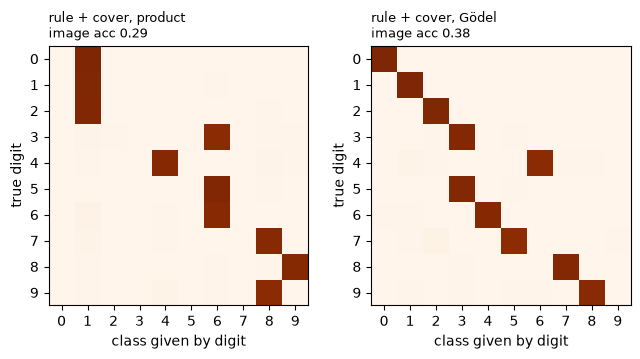

In [12]:
cover_prod = evaluate("rule + cover, product", less20k, "less", cover=True)
cover_godel = evaluate("rule + cover, Gödel", less20k, "less", semantics="godel", cover=True)
show_confusion([cover_prod, cover_godel])

- **Under product semantics the cover rule changes little** (test 0.857 against 0.854 without it; the same merged groups). Its ∃ is a probabilistic sum over the ~600 images of a batch, so it is easy to satisfy: if every image gives class `c` a 1% probability, "c appears" is 1 − 0.99⁶⁰⁰ ≈ 0.998, though no image is classified as `c`. The rule is satisfied without being obeyed.
- **Under Gödel semantics** (∃ = max), a class needs a high probability on at least one image, closer to what the rule means. The sequence accuracy rises to 0.95, but the digits are still wrong: 0–3 are right, 6–9 are shifted down (to 4, 5, 7, 8), 4 goes to class 6 and 5 merges with 3. The order of the digits is mostly kept, which is all `Less` checks, so the labels can't tell this labelling from the right one: it is still a reasoning shortcut, a milder one (image accuracy 0.38).

The choice of semantics decides whether a clause means what it says. Sequence labels alone don't pin the digits down here.

### 7.4 Second way out: 100 labelled digits

The usual remedy for reasoning shortcuts is a little supervision on the concepts. Here, 10 labelled images per class (the same 100 the probe uses), added as one clause: `DIGIT_LABELS = ∀ (li, ld): Is(digit(li), ld)`. Back to **800 sequences**, product semantics, no cover rule. The control: the 100 labelled digits alone, without the rule (sLTN still answers through the formula).

rule + 100 labelled digits         sequences: train 0.994, test 0.947, length 20 0.939 | image 0.948 | probe 0.944 (73s)


100 labelled digits only           sequences: train 0.820, test 0.826, length 20 0.794 | image 0.806 | probe 0.813 (17s)


GRU                                sequences: train 1.000, test 0.557, length 20 0.518 | image —     | probe 0.783 (21s)


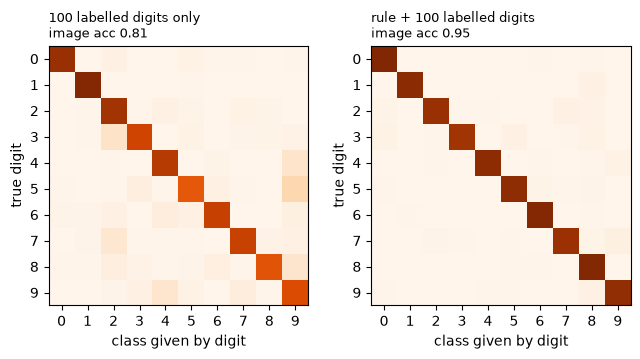

In [13]:
lab800 = evaluate("rule + 100 labelled digits", less800, "less", labels=True)
labonly800 = evaluate("100 labelled digits only", less800, "less", rule=False, labels=True)
gru800 = evaluate("GRU", less800, "less", model="gru")
show_confusion([labonly800, lab800])

- **The labels anchor the classes, and the rule does the rest.** The 100 labels alone give a mediocre classifier; with the rule on top, the 800 unlabelled sequences lift it to about 0.95, and the confusion matrix becomes the diagonal.
- **The GRU, with the same 800 sequences, is near chance.** It has no way to use the structure of the task.
- **Length 20 is as good as lengths 2–10**: the formula is the same at any length, so an sLTN model that knows the digits generalises to longer sequences for free.

### 7.5 The harder relation: x + y = z

The same three models on `Sum` at 800 sequences (6,000 steps: three images per step, and a table over triples).

In [14]:
sum800 = make_sets("sum", 800, CONFIG["seed"], pools)
sum_lab = evaluate("sum: rule + 100 labelled digits", sum800, "sum", labels=True)
sum_labonly = evaluate("sum: 100 labelled digits only", sum800, "sum", rule=False, labels=True)
sum_gru = evaluate("sum: GRU", sum800, "sum", model="gru")

sum: rule + 100 labelled digits    sequences: train 0.998, test 0.955, length 20 0.956 | image 0.967 | probe 0.960 (364s)


sum: 100 labelled digits only      sequences: train 0.754, test 0.765, length 20 0.747 | image 0.782 | probe 0.814 (52s)


sum: GRU                           sequences: train 1.000, test 0.557, length 20 0.530 | image —     | probe 0.760 (38s)


## 8. Results over 5 seeds and three dataset sizes

The same code, run beforehand on a T4 GPU for 5 seeds (0–4), both relations, and 800, 2,000 and 20,000 training sequences: sLTN with the rule and the 100 labelled digits, the GRU, and the labels-only control at 20,000 sequences. The next cell stores one row per run.

In [15]:
# One row per run, from the same code run on a T4 GPU (5 seeds).
SWEEP = dict(commit="124c1f8", device="Tesla T4",
             cols=('relation', 'n_train', 'model', 'seed', 'seq_acc', 'seq_acc_long', 'img_acc', 'probe_acc'),
             rows=[
    ('less', 800, 'sltn-prod-lab', 0, 0.954, 0.931, 0.949848, 0.936114),
    ('less', 800, 'gru', 0, 0.55, 0.525, None, 0.7829),
    ('less', 800, 'sltn-prod-lab', 1, 0.937, 0.935, 0.941245, 0.942739),
    ('less', 800, 'gru', 1, 0.623, 0.582, None, 0.767856),
    ('less', 800, 'sltn-prod-lab', 2, 0.943, 0.934, 0.947268, 0.951419),
    ('less', 800, 'gru', 2, 0.626, 0.573, None, 0.780153),
    ('less', 800, 'sltn-prod-lab', 3, 0.941, 0.944, 0.961148, 0.958684),
    ('less', 800, 'gru', 3, 0.561, 0.591, None, 0.794568),
    ('less', 800, 'sltn-prod-lab', 4, 0.949, 0.941, 0.94974, 0.951345),
    ('less', 800, 'gru', 4, 0.567, 0.583, None, 0.796911),
    ('less', 2000, 'sltn-prod-lab', 0, 0.951, 0.944, 0.952156, 0.966228),
    ('less', 2000, 'gru', 0, 0.594, 0.603, None, 0.807779),
    ('less', 2000, 'sltn-prod-lab', 1, 0.958, 0.964, 0.969737, 0.964094),
    ('less', 2000, 'gru', 1, 0.647, 0.602, None, 0.815325),
    ('less', 2000, 'sltn-prod-lab', 2, 0.968, 0.967, 0.975261, 0.965724),
    ('less', 2000, 'gru', 2, 0.681, 0.642, None, 0.831482),
    ('less', 2000, 'sltn-prod-lab', 3, 0.956, 0.966, 0.970661, 0.96516),
    ('less', 2000, 'gru', 3, 0.664, 0.665, None, 0.852845),
    ('less', 2000, 'sltn-prod-lab', 4, 0.965, 0.957, 0.969335, 0.966069),
    ('less', 2000, 'gru', 4, 0.596, 0.637, None, 0.824311),
    ('less', 20000, 'sltn-prod-lab', 0, 0.982, 0.976, 0.97968, 0.980693),
    ('less', 20000, 'gru', 0, 0.916, 0.904, None, 0.932286),
    ('less', 20000, 'sltn-prod-labonly', 0, 0.824, 0.796, 0.790724, 0.808173),
    ('less', 20000, 'sltn-prod-lab', 1, 0.973, 0.969, 0.972559, 0.97953),
    ('less', 20000, 'gru', 1, 0.894, 0.897, None, 0.925035),
    ('less', 20000, 'sltn-prod-labonly', 1, 0.797, 0.801, 0.79314, 0.795795),
    ('less', 20000, 'sltn-prod-lab', 2, 0.968, 0.97, 0.975373, 0.978795),
    ('less', 20000, 'gru', 2, 0.928, 0.891, None, 0.92999),
    ('less', 20000, 'sltn-prod-labonly', 2, 0.823, 0.818, 0.817009, 0.822226),
    ('less', 20000, 'sltn-prod-lab', 3, 0.974, 0.966, 0.976162, 0.97662),
    ('less', 20000, 'gru', 3, 0.898, 0.908, None, 0.928027),
    ('less', 20000, 'sltn-prod-labonly', 3, 0.819, 0.823, 0.810956, 0.831643),
    ('less', 20000, 'sltn-prod-lab', 4, 0.975, 0.974, 0.980461, 0.979021),
    ('less', 20000, 'gru', 4, 0.934, 0.917, None, 0.930256),
    ('less', 20000, 'sltn-prod-labonly', 4, 0.825, 0.811, 0.798683, 0.808314),
    ('sum', 800, 'sltn-prod-lab', 0, 0.935, 0.944, 0.95921, 0.954035),
    ('sum', 800, 'gru', 0, 0.543, 0.54, None, 0.762771),
    ('sum', 800, 'sltn-prod-lab', 1, 0.931, 0.927, 0.945213, 0.957852),
    ('sum', 800, 'gru', 1, 0.578, 0.572, None, 0.766477),
    ('sum', 800, 'sltn-prod-lab', 2, 0.941, 0.949, 0.960204, 0.955103),
    ('sum', 800, 'gru', 2, 0.576, 0.561, None, 0.802421),
    ('sum', 800, 'sltn-prod-lab', 3, 0.936, 0.956, 0.961605, 0.965661),
    ('sum', 800, 'gru', 3, 0.59, 0.563, None, 0.801374),
    ('sum', 800, 'sltn-prod-lab', 4, 0.934, 0.929, 0.950904, 0.956909),
    ('sum', 800, 'gru', 4, 0.566, 0.562, None, 0.786989),
    ('sum', 2000, 'sltn-prod-lab', 0, 0.958, 0.962, 0.973957, 0.971842),
    ('sum', 2000, 'gru', 0, 0.58, 0.574, None, 0.787479),
    ('sum', 2000, 'sltn-prod-lab', 1, 0.972, 0.968, 0.973637, 0.971196),
    ('sum', 2000, 'gru', 1, 0.615, 0.586, None, 0.810578),
    ('sum', 2000, 'sltn-prod-lab', 2, 0.968, 0.956, 0.975114, 0.975338),
    ('sum', 2000, 'gru', 2, 0.57, 0.58, None, 0.787736),
    ('sum', 2000, 'sltn-prod-lab', 3, 0.967, 0.974, 0.976368, 0.97042),
    ('sum', 2000, 'gru', 3, 0.608, 0.62, None, 0.795641),
    ('sum', 2000, 'sltn-prod-lab', 4, 0.964, 0.97, 0.973534, 0.962858),
    ('sum', 2000, 'gru', 4, 0.595, 0.59, None, 0.817459),
    ('sum', 20000, 'sltn-prod-lab', 0, 0.976, 0.981, 0.987702, 0.983918),
    ('sum', 20000, 'gru', 0, 0.817, 0.821, None, 0.927935),
    ('sum', 20000, 'sltn-prod-labonly', 0, 0.79, 0.774, 0.809794, 0.823595),
    ('sum', 20000, 'sltn-prod-lab', 1, 0.984, 0.982, 0.986927, 0.983076),
    ('sum', 20000, 'gru', 1, 0.812, 0.819, None, 0.917223),
    ('sum', 20000, 'sltn-prod-labonly', 1, 0.769, 0.738, 0.770708, 0.799403),
    ('sum', 20000, 'sltn-prod-lab', 2, 0.982, 0.974, 0.983465, 0.983129),
    ('sum', 20000, 'gru', 2, 0.818, 0.819, None, 0.917381),
    ('sum', 20000, 'sltn-prod-labonly', 2, 0.773, 0.767, 0.809484, 0.822768),
    ('sum', 20000, 'sltn-prod-lab', 3, 0.983, 0.988, 0.988482, 0.984534),
    ('sum', 20000, 'gru', 3, 0.832, 0.801, None, 0.924454),
    ('sum', 20000, 'sltn-prod-labonly', 3, 0.81, 0.796, 0.842094, 0.837173),
    ('sum', 20000, 'sltn-prod-lab', 4, 0.98, 0.98, 0.987267, 0.983987),
    ('sum', 20000, 'gru', 4, 0.822, 0.822, None, 0.922713),
    ('sum', 20000, 'sltn-prod-labonly', 4, 0.765, 0.759, 0.809119, 0.840423),
])

In [16]:
rows = [dict(zip(SWEEP["cols"], r)) for r in SWEEP["rows"]]
print("sweep: sltn", SWEEP["commit"], "on", SWEEP["device"], "|", len(rows), "runs\n")
groups = {}
for r in rows:
    groups.setdefault((r["relation"], r["n_train"], r["model"]), []).append(r)


def ms(rel, n, model, key):
    v = [r[key] for r in groups.get((rel, n, model), [])]
    return (np.mean(v), np.std(v)) if v else (np.nan, np.nan)


fmt = lambda m_s: "—" if np.isnan(m_s[0]) else f"{m_s[0]:.3f} ± {m_s[1]:.3f}"
print(f"{'relation':9s}{'sequences':>10s} | {'sLTN: seq / length 20 / image':>40s} | {'labels only: seq / image':>28s} | GRU: seq / probe")
for rel in ("less", "sum"):
    for n in (800, 2000, 20000):
        s = " / ".join(fmt(ms(rel, n, "sltn-prod-lab", k)) for k in ("seq_acc", "seq_acc_long", "img_acc"))
        lo = " / ".join(fmt(ms(rel, n, "sltn-prod-labonly", k)) for k in ("seq_acc", "img_acc"))
        g = " / ".join(fmt(ms(rel, n, "gru", k)) for k in ("seq_acc", "probe_acc"))
        print(f"{rel:9s}{n:>10,d} | {s:>40s} | {lo:>28s} | {g}")

sweep: sltn 124c1f8 on Tesla T4 | 70 runs

relation  sequences |            sLTN: seq / length 20 / image |     labels only: seq / image | GRU: seq / probe
less            800 | 0.945 ± 0.006 / 0.937 ± 0.005 / 0.950 ± 0.006 |                        — / — | 0.585 ± 0.032 / 0.784 ± 0.011
less          2,000 | 0.960 ± 0.006 / 0.960 ± 0.009 / 0.967 ± 0.008 |                        — / — | 0.636 ± 0.035 / 0.826 ± 0.015
less         20,000 | 0.974 ± 0.004 / 0.971 ± 0.004 / 0.977 ± 0.003 | 0.818 ± 0.010 / 0.802 ± 0.010 | 0.914 ± 0.016 / 0.929 ± 0.002
sum             800 | 0.935 ± 0.003 / 0.941 ± 0.011 / 0.955 ± 0.006 |                        — / — | 0.571 ± 0.016 / 0.784 ± 0.017
sum           2,000 | 0.966 ± 0.005 / 0.966 ± 0.006 / 0.975 ± 0.001 |                        — / — | 0.594 ± 0.017 / 0.800 ± 0.012
sum          20,000 | 0.981 ± 0.003 / 0.981 ± 0.004 / 0.987 ± 0.002 | 0.781 ± 0.017 / 0.808 ± 0.023 | 0.820 ± 0.007 / 0.922 ± 0.004


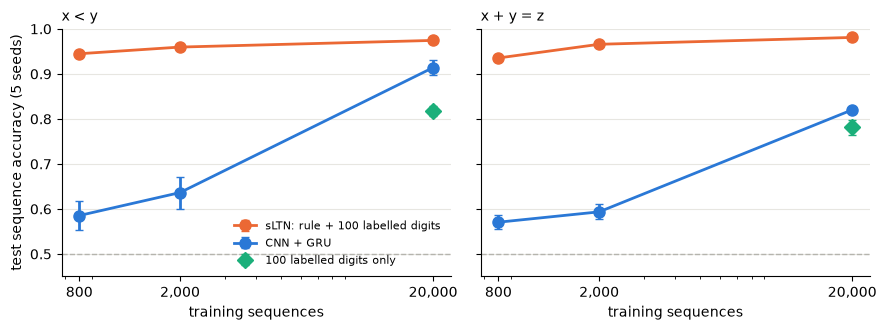

In [17]:
sizes = [800, 2000, 20000]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, rel in zip(axes, ("less", "sum")):
    for model, label, color in [("sltn-prod-lab", "sLTN: rule + 100 labelled digits", COLORS["sltn"]),
                                ("gru", "CNN + GRU", COLORS["gru"])]:
        m = [ms(rel, n, model, "seq_acc") for n in sizes]
        ax.errorbar(sizes, [v[0] for v in m], yerr=[v[1] for v in m], color=color, lw=2, marker="o", ms=8,
                    capsize=3, label=label)
    lo = ms(rel, 20000, "sltn-prod-labonly", "seq_acc")
    ax.errorbar([20000], [lo[0]], yerr=[lo[1]], color=COLORS["labonly"], marker="D", ms=8, lw=0, elinewidth=2,
                capsize=3, label="100 labelled digits only")
    ax.axhline(0.5, color="#b5b4ad", lw=1, ls="--")
    ax.set_xscale("log"); ax.set_xticks(sizes); ax.set_xticklabels(["800", "2,000", "20,000"])
    ax.set_xlabel("training sequences"); ax.set_title("x < y" if rel == "less" else "x + y = z", fontsize=10, loc="left")
    ax.grid(axis="y", color="#e7e6e1", lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("test sequence accuracy (5 seeds)"); axes[0].set_ylim(0.45, 1.0)
axes[0].legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 9. Findings

Seed 0 in Section 7 (trained in this notebook); 5 seeds in Section 8 (run beforehand on a T4 GPU, sLTN `124c1f8`). Single-seed numbers are from the run of this notebook (A40 GPU, 2026-11-04).

**1. Sequence labels alone don't teach the digits.**
- At 800 sequences sLTN memorises: every training sequence right, test accuracy about 0.65, image accuracy at chance.
- At 20,000 it falls into a reasoning shortcut: test accuracy about 0.85 and a probe of 0.95, but `digit` merges the digits into ordered groups (image accuracy about 0.1).
- The GRU behaves the same way: near chance at 800 and 2,000 sequences (0.57–0.64).

**2. The semantics decides whether a clause means what it says.** "Every class is used" is satisfied for free under the probabilistic sum and works better under Gödel's max (sequence accuracy about 0.95), but the digits are still a reasoning shortcut: the order is mostly kept, several digits are shifted or merged (image accuracy 0.38).

**3. With 100 labelled digits and the rule, sLTN learns both relations from few sequences.**
- 0.945 ± 0.006 (`Less`) and 0.935 ± 0.003 (`Sum`) sequence accuracy at 800 sequences, 0.974 and 0.981 at 20,000; image accuracy 0.95–0.99.
- **The rule does the work:** the 100 labels alone give 0.80–0.81 image accuracy even with 20,000 sequences available; with the rule, 0.95 at 800 and 0.98–0.99 at 20,000.
- **Data efficiency:** sLTN at 800 sequences beats the GRU at 20,000 (`Less` 0.945 vs 0.914, `Sum` 0.935 vs 0.820).
- **Length generalisation:** length 20 within one point of lengths 2–10, for every size and both relations.
- **Reliable:** the std over seeds is at most 0.008 for sLTN, up to 0.035 for the GRU.

**4. Product semantics needs aggregators that sLTN doesn't ship.** ∀ over the steps must be strict (a p-mean gives a sequence with one trigger without a response 0.59); the product and the probabilistic sum take 10 lines each (Section 4).

**Limits:**
- **Synthetic labels:** the rule is exactly how the labels were made, and the relations are fixed tables.
- **Concept supervision is needed.** Without the 100 labelled digits, the sequence labels don't identify the digits; this is a property of the task (several labellings satisfy it almost equally), not of sLTN, and ∂LTLf's benchmark doesn't face it because its propositions are about single images.
- **One rule** (Declare's Response). Response + Precedence, where a "no" doesn't say which rule failed, is the natural next setting.
- **One baseline** (CNN + GRU, with a tuned learning rate); no Transformer, and no comparison with ∂LTLf itself, whose language has no relations between images.